<a href="https://colab.research.google.com/github/Sarah-Jack05/encs4380-dynamics--Mazion-/blob/main/pid_my_system_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ENCS4380 - PARTNER 3 PID SYSTEM

VALIDATION CHECK 1 - P CONTROLLER
---------------------------------
Kp = 9.0
Closed-loop time constant = 0.100 s
Steady-state error = 10.00%
Expected time constant = 0.100 s
Expected steady-state error = 10.00%
STATUS: PASS

VALIDATION CHECK 2 - PI CONTROLLER
----------------------------------
Kp = 1.0
Ki = 1.0
Natural frequency = 1.000 rad/s
Damping ratio = 1.000
Steady-state error = 0.000000%
Overshoot = 0.0000%
STATUS: PASS


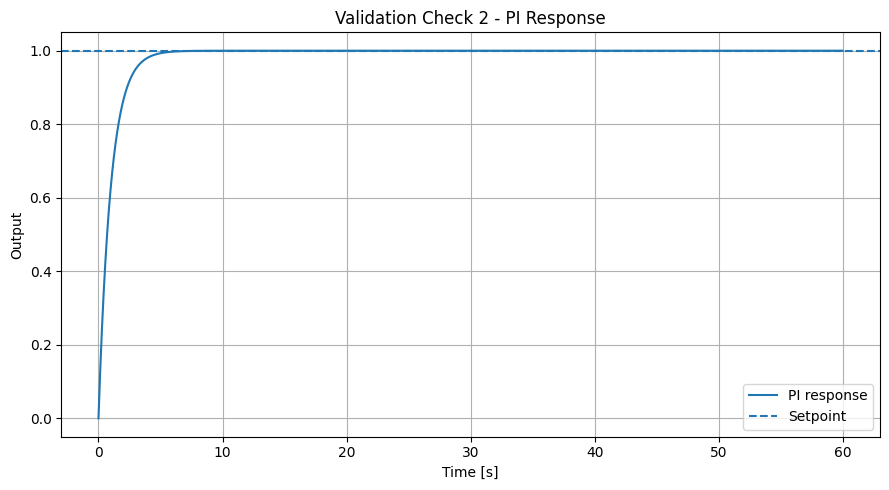


PI Controller 1
Kp = 1.0
Ki = 1.0
Final output = 1.000000
Steady-state error = 0.000000%

PI Controller 2
Kp = 2.0
Ki = 0.5
Final output = 0.999992
Steady-state error = 0.000755%


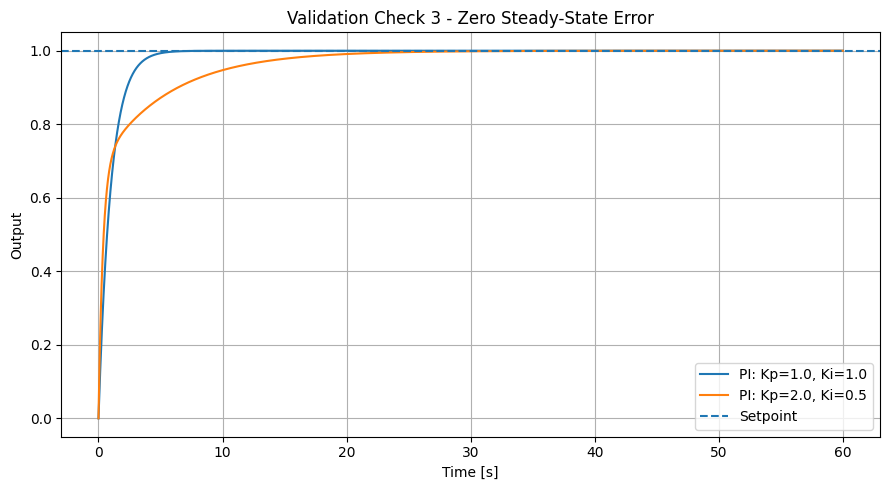


CHECK 3 STATUS: PASS

VALIDATION SUMMARY
------------------
Check 1: PASS
Check 2: PASS
Check 3: PASS

Using temporary placeholder values for simulation.
These values are NOT real motor measurements.

Parameter source: Placeholder simulation values

PID GAIN DESIGN
----------------
Target damping ratio = 0.700
Natural frequency = 20.0000 rad/s
Kp = 0.900000
Ki = 20.000000
Kd = 0.000000
Calculated damping ratio = 0.7000

MICROMOUSE PID PERFORMANCE
--------------------------
Plant gain K = 2.000000
Time constant tau = 0.100000 s
Kp = 0.900000
Ki = 20.000000
Kd = 0.000000
Damping ratio = 0.7000

Performance Metrics
Final speed = 40.0000 mm/s
Rise time = 0.0660 s
Overshoot = 9.46%
Settling time = 0.2550 s
Steady-state error = 0.0000 mm/s

PWM Results
Minimum PWM = 19.22%
Maximum PWM = 37.68%
PWM constraint: PASS


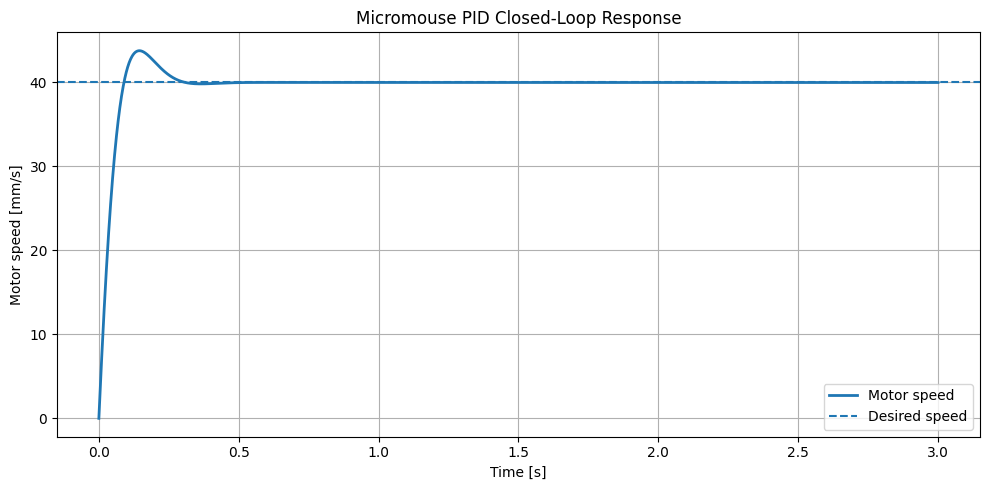

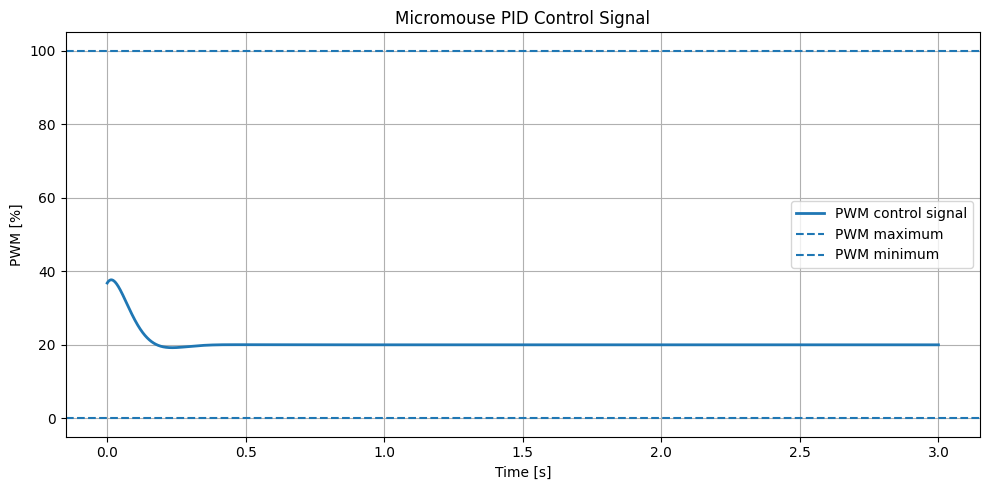


Arduino code saved to: generated_micromouse_pid.ino
Connect readMotorSpeed() and setMotorPWM()
to your actual encoder and motor-driver functions.

PROGRAM FINISHED


In [4]:

# ============================================================
# 11. MAIN PROGRAM
# ============================================================

def main():

    print("=" * 60)
    print("ENCS4380 - PARTNER 3 PID SYSTEM")
    print("=" * 60)

    # --------------------------------------------------------
    # Run all three homework validation checks.
    # --------------------------------------------------------

    check_1 = validation_check_1()
    check_2 = validation_check_2()
    check_3 = validation_check_3()

    print("\nVALIDATION SUMMARY")
    print("------------------")
    print("Check 1:", "PASS" if check_1 else "FAIL")
    print("Check 2:", "PASS" if check_2 else "FAIL")
    print("Check 3:", "PASS" if check_3 else "FAIL")

    # --------------------------------------------------------
    # Identify motor parameters.
    # Use real CSV data if available.
    # Otherwise, use temporary placeholder values.
    # --------------------------------------------------------

    if os.path.exists(CSV_FILE):

        print("\nUsing real motor test data...")

        K, tau = identify_motor_parameters(CSV_FILE)

        parameter_source = "Real encoder measurements"

    else:

        print("\nWARNING: Motor CSV file was not found.")
        print("Using temporary placeholder values for simulation.")
        print("These values are NOT real motor measurements.")

        K = 2.0
        tau = 0.10

        parameter_source = "Placeholder simulation values"

    print("\nParameter source:", parameter_source)

    # --------------------------------------------------------
    # Calculate PID gains.
    # --------------------------------------------------------

    Kp, Ki, Kd, zeta = calculate_pid_gains(K, tau)

    # --------------------------------------------------------
    # Simulate the motor under PID control.
    # --------------------------------------------------------

    t, y, u, error = simulate_motor_pid(
        K, tau, Kp, Ki, Kd
    )

    # --------------------------------------------------------
    # Calculate performance metrics.
    # --------------------------------------------------------

    metrics = calculate_metrics(t, y, u)

    print("\nMICROMOUSE PID PERFORMANCE")
    print("--------------------------")
    print(f"Plant gain K = {K:.6f}")
    print(f"Time constant tau = {tau:.6f} s")
    print(f"Kp = {Kp:.6f}")
    print(f"Ki = {Ki:.6f}")
    print(f"Kd = {Kd:.6f}")
    print(f"Damping ratio = {zeta:.4f}")

    print("\nPerformance Metrics")
    print(f"Final speed = {metrics['final_speed']:.4f} mm/s")
    print(f"Rise time = {metrics['rise_time']:.4f} s")
    print(f"Overshoot = {metrics['overshoot']:.2f}%")
    print(f"Settling time = {metrics['settling_time']:.4f} s")
    print(
        f"Steady-state error = "
        f"{metrics['steady_state_error']:.4f} mm/s"
    )

    print("\nPWM Results")
    print(f"Minimum PWM = {metrics['minimum_pwm']:.2f}%")
    print(f"Maximum PWM = {metrics['maximum_pwm']:.2f}%")
    print(
        "PWM constraint:",
        "PASS" if metrics["pwm_ok"] else "FAIL"
    )

    # --------------------------------------------------------
    # Plot motor response.
    # --------------------------------------------------------

    plt.figure(figsize=(10, 5))

    plt.plot(
        t, y,
        linewidth=2,
        label="Motor speed"
    )

    plt.axhline(
        SETPOINT,
        linestyle="--",
        label="Desired speed"
    )

    plt.xlabel("Time [s]")
    plt.ylabel("Motor speed [mm/s]")
    plt.title("Micromouse PID Closed-Loop Response")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Plot PWM control signal.
    # --------------------------------------------------------

    plt.figure(figsize=(10, 5))

    plt.plot(
        t, u,
        linewidth=2,
        label="PWM control signal"
    )

    plt.axhline(
        PWM_MAX,
        linestyle="--",
        label="PWM maximum"
    )

    plt.axhline(
        PWM_MIN,
        linestyle="--",
        label="PWM minimum"
    )

    plt.xlabel("Time [s]")
    plt.ylabel("PWM [%]")
    plt.title("Micromouse PID Control Signal")
    plt.ylim(-5, 105)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Generate Arduino PID code.
    # --------------------------------------------------------

    generate_arduino_code(Kp, Ki, Kd)

    print("\nPROGRAM FINISHED")
    print("=" * 60)


# ============================================================
# RUN PROGRAM
# ============================================================

if __name__ == "__main__":
    main()
